# Tema 4 · Gestión de capital y medidas coherentes de riesgo (VaR / TVaR) — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) Caso 1 Normal y tabla VaR/TVaR por nivel (taller de Excel), (B) extensión Log-normal y distribuciones de cola pesada,
(C) bonos correlacionados: no-subaditividad del VaR (Caso 2 de crédito), (D) demostración por simulación (taller de R),
(E) asignación de capital de Euler, (F) agregación de la fórmula estándar frente a la distribución conjunta,
(G) VaR frente a TVaR: error de estimación y equivalencia de niveles.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize, integrate

def var_tvar_normal(p, mu, sd):
    z = stats.norm.ppf(p); return mu + sd*z, mu + sd*stats.norm.pdf(z)/(1 - p)

def var_tvar_lognormal(p, E, sd):
    s2 = np.log(1 + (sd/E)**2); s = s2**.5; m = np.log(E) - s2/2; z = stats.norm.ppf(p)
    return np.exp(m + s*z), E*stats.norm.cdf(s - z)/(1 - p), (m, s)

def tvar_numerico(ppf, p, n=20000):
    """TVaR = (1/(1−p)) ∫_p^1 VaR_u du por regla del punto medio (forma integral de la diapositiva)."""
    u = p + (1 - p)*(np.arange(n) + .5)/n; return ppf(u).mean()

## (A) Caso 1 — S ~ Normal(5.000.000; 800.000): VaR y TVaR por nivel de confianza
$VaR_p=\mu+\sigma z_p$, $TVaR_p=\mu+\sigma\,\varphi(z_p)/(1-p)$. Se comprueba además la forma integral $\frac1{1-p}\int_p^1VaR_u\,du$ y la de Rockafellar–Uryasev $\min_t\{t+E[(X-t)^+]/(1-p)\}$.

In [2]:
mu, sd = 5_000_000, 800_000
niveles = [.95, .99, .995, .999]
filas = []
for p in niveles:
    v, t = var_tvar_normal(p, mu, sd)
    t_int = tvar_numerico(lambda u: stats.norm.ppf(u, mu, sd), p)
    # Rockafellar–Uryasev: E[(X−t)^+] para Normal = (μ−t)Φ(−d) + σφ(d)... se calcula por integración numérica
    ru = optimize.minimize_scalar(lambda tt: tt + integrate.quad(lambda x: (x - tt)*stats.norm.pdf(x, mu, sd), tt, mu + 12*sd)[0]/(1 - p),
                                  bracket=(v - 1e5, v + 1e5)).fun
    filas.append([p, v, t, t - v, t/v - 1, t_int, ru])
tab = pd.DataFrame(filas, columns=["p", "VaR", "TVaR", "TVaR−VaR", "TVaR/VaR−1", "TVaR (integral)", "TVaR (Rockafellar–Uryasev)"]).set_index("p")
tab["Capital VaR"] = tab.VaR - mu; tab["Capital TVaR"] = tab.TVaR - mu; tab["Capital TVaR/VaR −1 %"] = 100*(tab["Capital TVaR"]/tab["Capital VaR"] - 1)
pd.options.display.float_format = "{:,.4f}".format
tab.round(4)

,VaR,TVaR,TVaR−VaR,TVaR/VaR−1,TVaR (integral),TVaR (Rockafellar–Uryasev),Capital VaR,Capital TVaR,Capital TVaR/VaR −1 %
p,,,,,,,,,
0.9500,"6,315,882.9016","6,650,170.2460","334,287.3444",0.0529,"6,650,167.5721","6,650,170.2460","1,315,882.9016","1,650,170.2460",25.4040
0.9900,"6,861,078.2992","7,132,171.3763","271,093.0770",0.0395,"7,132,168.8454","7,132,171.3763","1,861,078.2992","2,132,171.3763",14.5665
0.9950,"7,060,663.4428","7,313,558.8843","252,895.4415",0.0358,"7,313,556.4084","7,313,558.8843","2,060,663.4428","2,313,558.8843",12.2725
0.9990,"7,472,185.8449","7,693,672.0617","221,486.2167",0.0296,"7,693,669.7010","7,693,672.0617","2,472,185.8449","2,693,672.0617",8.9591


**Lectura.** Al 99,5 %: VaR 7.060.663, TVaR 7.313.559; el TVaR exige un **12,3 % más de capital** (sobre la media) y un 3,6 % más en valor. Con la Normal la brecha $TVaR-VaR$ **decrece** con $p$ (334.287 al 95 % → 221.486 al 99,9 %). Las tres formas de calcular el TVaR coinciden.

## (B) Extensión: Log-normal con la misma media y varianza, y colas más pesadas
$\sigma_L^2=\ln[1+(\sigma/E)^2]$, $\mu_L=\ln E-\sigma_L^2/2$; $TVaR=E\cdot\Phi(\sigma_L-z_p)/(1-p)$. Se añade una Student-$t$ con 4 grados de libertad (misma media y desviación) y una Pareto con índice $\alpha$ para ver cuándo la brecha **crece** con $p$.

In [3]:
rows = []
for p in niveles + [.9999]:
    vn, tn = var_tvar_normal(p, mu, sd); vl, tl, par = var_tvar_lognormal(p, mu, sd)
    nu = 4; sc = sd*np.sqrt((nu - 2)/nu); tq = stats.t.ppf(p, nu)
    vt = mu + sc*tq; tt = mu + sc*(stats.t.pdf(tq, nu)/(1 - p))*((nu + tq**2)/(nu - 1))
    rows.append([p, vn, tn, tn - vn, vl, tl, tl - vl, vt, tt, tt - vt])
cmp_ = pd.DataFrame(rows, columns=["p", "VaR N", "TVaR N", "brecha N", "VaR LN", "TVaR LN", "brecha LN", "VaR t4", "TVaR t4", "brecha t4"]).set_index("p")
sl2 = par[1]**2
print(f"Log-normal: σ_L² = {sl2:.5f}  σ_L = {par[1]:.5f}  μ_L = {par[0]:.5f}")
v5, t5, _ = var_tvar_lognormal(.995, mu, sd)
print(f"Log-normal 99,5 %: VaR = {v5:,.0f}  TVaR = {t5:,.0f}  capital VaR = {v5 - mu:,.0f}  capital TVaR = {t5 - mu:,.0f}  (+{100*((t5 - mu)/(v5 - mu) - 1):.1f} % TVaR sobre VaR)")
print(f"Frente a la Normal: capital VaR +{100*((v5 - mu)/(var_tvar_normal(.995, mu, sd)[0] - mu) - 1):.1f} %, capital TVaR +{100*((t5 - mu)/(var_tvar_normal(.995, mu, sd)[1] - mu) - 1):.1f} %")
cmp_.round(0)

Log-normal: σ_L² = 0.02528  σ_L = 0.15899  μ_L = 15.41231
Log-normal 99,5 %: VaR = 7,435,977  TVaR = 7,827,963  capital VaR = 2,435,977  capital TVaR = 2,827,963  (+16.1 % TVaR sobre VaR)
Frente a la Normal: capital VaR +18.2 %, capital TVaR +22.2 %


,VaR N,TVaR N,brecha N,VaR LN,TVaR LN,brecha LN,VaR t4,TVaR t4,brecha t4
p,,,,,,,,,
0.9500,"6,315,883.0000","6,650,170.0000","334,287.0000","6,412,917.0000","6,865,759.0000","452,842.0000","6,205,955.0000","6,811,817.0000","605,862.0000"
0.9900,"6,861,078.0000","7,132,171.0000","271,093.0000","7,146,802.0000","7,551,893.0000","405,092.0000","7,119,594.0000","7,953,208.0000","833,615.0000"
0.9950,"7,060,663.0000","7,313,559.0000","252,895.0000","7,435,977.0000","7,827,963.0000","391,985.0000","7,604,469.0000","8,577,865.0000","973,395.0000"
0.9990,"7,472,186.0000","7,693,672.0000","221,486.0000","8,069,689.0000","8,440,232.0000","370,544.0000","9,057,765.0000","10,479,353.0000","1,421,588.0000"
0.9999,"7,975,213.0000","8,166,784.0000","191,571.0000","8,918,121.0000","9,270,433.0000","352,312.0000","12,372,958.0000","14,869,003.0000","2,496,045.0000"


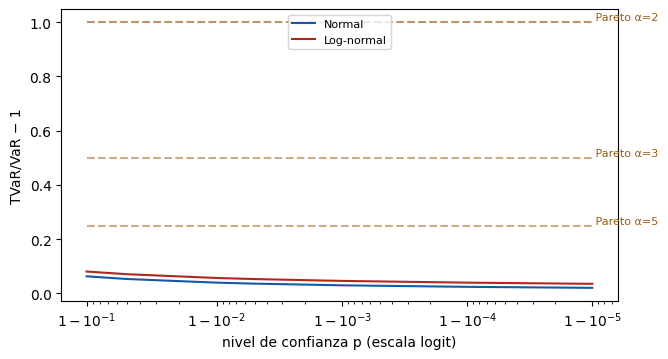

In [4]:
# Brecha TVaR − VaR relativa al VaR en el límite p→1: Normal → 0 ; Log-normal → 0 (lentamente) ; Pareto → 1/(α−1)
ps = np.array([.9, .95, .99, .995, .999, .9999, .99999])
fig, ax = plt.subplots(figsize=(6.8, 3.7))
for al in (2, 3, 5):
    ax.plot(ps, np.full_like(ps, 1/(al - 1)), "--", color="#9a5b12", alpha=.5 + .15*(al == 2))
    ax.text(ps[-1], 1/(al - 1), f" Pareto α={al}", fontsize=8, color="#9a5b12", va="bottom")
ax.plot(ps, [(var_tvar_normal(p, mu, sd)[1]/var_tvar_normal(p, mu, sd)[0] - 1) for p in ps], color="#1559a6", label="Normal")
ax.plot(ps, [(var_tvar_lognormal(p, mu, sd)[1]/var_tvar_lognormal(p, mu, sd)[0] - 1) for p in ps], color="#b3261e", label="Log-normal")
ax.set_xscale("logit"); ax.set_xlabel("nivel de confianza p (escala logit)"); ax.set_ylabel("TVaR/VaR − 1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** Con la Log-normal (misma media y varianza) el capital sube un 18,2 % (VaR) y un 22,2 % (TVaR) frente a la Normal, y la prima del TVaR sobre el VaR pasa del 12,3 % al 16,1 %.
La afirmación de la diapositiva de que, con cola pesada, la brecha «aumenta con $p$» solo es cierta para colas realmente pesadas (Pareto: $TVaR_p/VaR_p\to\alpha/(\alpha-1)$, brecha $VaR_p/(\alpha-1)$ creciente);
con esta Log-normal suave la brecha absoluta también decrece, aunque mucho más despacio que con la Normal.

## (C) Bonos correlacionados: el VaR no es subaditivo, el TVaR sí
Dos bonos con $q=2\,\%$ y pérdida 100; $P(A=1,B=1)=q^2+\rho\,q(1-q)$; $p=97{,}5\,\%$. Se calcula la distribución de $S=100(A+B)$ para cada $\rho$ y se obtienen VaR y TVaR exactos.

In [5]:
def bonos(rho, q=.02, L=100, p=.975):
    p11 = q**2 + rho*q*(1 - q); p10 = q - p11; p00 = 1 - 2*q + p11
    xs = np.array([0, L, 2*L]); pr = np.array([p00, 2*p10, p11])
    cdf = np.cumsum(pr); var = xs[np.searchsorted(cdf, p - 1e-12)]
    exc = np.sum(np.maximum(xs - var, 0)*pr); tvar = var + exc/(1 - p)
    return p11, 1 - p00, var, tvar
def bono_individual(q=.02, L=100, p=.975):
    xs = np.array([0, L]); pr = np.array([1 - q, q]); var = xs[np.searchsorted(np.cumsum(pr), p - 1e-12)]
    return var, var + np.sum(np.maximum(xs - var, 0)*pr)/(1 - p)
vi, ti = bono_individual()
out = []
for rho in (0, .25, .5, .75, 1.0):
    p11, pS, v, t = bonos(rho); out.append([rho, 100*p11, 100*pS, v, 2*vi, t, 2*ti, 2*ti - t])
rb = pd.DataFrame(out, columns=["ρ", "P(A y B) %", "P(S>0) %", "VaR A+B", "VaR A + VaR B", "TVaR A+B", "TVaR A + TVaR B", "beneficio TVaR"]).set_index("ρ")
rho_star = (0.015 - .02**2)/(.02*.98)
print(f"VaR individual = {vi}, TVaR individual = {ti};  umbral ρ* = {rho_star:.4f}  rango admisible ρ ∈ [{-.02/.98:.4f}, 1]")
rb.round(2)

VaR individual = 0, TVaR individual = 79.99999999999993;  umbral ρ* = 0.7449  rango admisible ρ ∈ [-0.0204, 1]


,P(A y B) %,P(S>0) %,VaR A+B,VaR A + VaR B,TVaR A+B,TVaR A + TVaR B,beneficio TVaR
ρ,,,,,,,
0.0000,0.0400,3.9600,100,0,101.6000,160.0000,58.4000
0.2500,0.5300,3.4700,100,0,121.2000,160.0000,38.8000
0.5000,1.0200,2.9800,100,0,140.8000,160.0000,19.2000
0.7500,1.5100,2.4900,0,0,160.0000,160.0000,0.0000
1.0000,2.0000,2.0000,0,0,160.0000,160.0000,0.0000


**Lectura.** Para $\rho<\rho^*\approx0{,}745$ el VaR de la cartera es 100 mientras la suma de VaR individuales es 0: **no es subaditivo**, y el VaR *cae* de golpe a 0 en $\rho^*$ (discontinuidad). El TVaR crece de forma continua con $\rho$, nunca supera 160 (comonotonía) y el beneficio de diversificación baja de 58,4 a 0.
**Caso 2 de crédito del banco** (50 M€ por cartera, $q=1{,}5\,\%$, independientes, $p=98\,\%$):

In [6]:
def credito(q=.015, E=50., p=.98):
    p2, p1, p0 = q**2, 2*q*(1 - q), (1 - q)**2
    xs = np.array([0, E, 2*E]); pr = np.array([p0, p1, p2]); cdf = np.cumsum(pr)
    v = xs[np.searchsorted(cdf, p - 1e-12)]; t = v + np.sum(np.maximum(xs - v, 0)*pr)/(1 - p)
    vi = 0.0; ti = q*E/(1 - p)                                       # VaR individual = 0 (q < 1−p); TVaR = q·E/(1−p)
    return dict(VaR_A=vi, VaR_B=vi, VaR_AB=v, TVaR_A=ti, TVaR_B=ti, TVaR_AB=t, P_alguno=1 - p0)
c2 = credito(); print({k: round(v, 4) for k, v in c2.items()})
print(f"VaR: 0+0 = 0 < {c2['VaR_AB']:.0f} (no subaditivo)   TVaR: {c2['TVaR_A'] + c2['TVaR_B']:.1f} ≥ {c2['TVaR_AB']:.4f} (subaditivo, beneficio {c2['TVaR_A'] + c2['TVaR_B'] - c2['TVaR_AB']:.2f})")

{'VaR_A': 0.0, 'VaR_B': 0.0, 'VaR_AB': np.float64(50.0), 'TVaR_A': 37.5, 'TVaR_B': 37.5, 'TVaR_AB': np.float64(50.5625), 'P_alguno': 0.0298}
VaR: 0+0 = 0 < 50 (no subaditivo)   TVaR: 75.0 ≥ 50.5625 (subaditivo, beneficio 24.44)


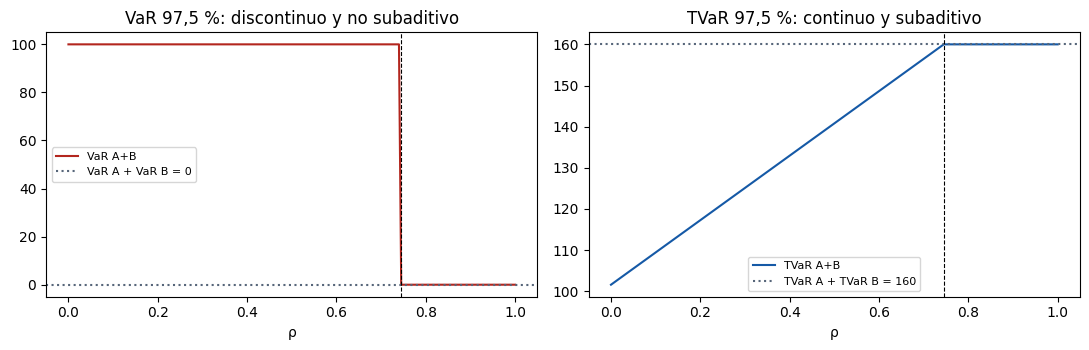

In [7]:
rr = np.linspace(0, 1, 201); res = np.array([bonos(r_) for r_ in rr])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(rr, res[:, 2], color="#b3261e", label="VaR A+B"); ax[0].axhline(0, color="#57667a", ls=":", label="VaR A + VaR B = 0")
ax[0].axvline(rho_star, color="k", ls="--", lw=.8); ax[0].set_title("VaR 97,5 %: discontinuo y no subaditivo"); ax[0].set_xlabel("ρ"); ax[0].legend(fontsize=8)
ax[1].plot(rr, res[:, 3], color="#1559a6", label="TVaR A+B"); ax[1].axhline(2*ti, color="#57667a", ls=":", label="TVaR A + TVaR B = 160")
ax[1].axvline(rho_star, color="k", ls="--", lw=.8); ax[1].set_title("TVaR 97,5 %: continuo y subaditivo"); ax[1].set_xlabel("ρ"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## (D) Demostración por simulación (taller de R): $VaR$ y $ES$ de $0{,}5A+0{,}5B$
Dos carteras independientes: pérdida $1$ con probabilidad $q=1{,}5\,\%$ y ruido $N(0;0{,}001)$ en el resto; cartera equiponderada; 100.000 escenarios; método histórico al 98 %.

In [8]:
def var_hist(x, p): return np.quantile(x, p)
def es_hist(x, p): v = np.quantile(x, p); return x[x >= v].mean()
rng = np.random.default_rng(456); n_sim = 100_000; q = .015
LA = np.where(rng.random(n_sim) < q, 1.0, rng.normal(0, .001, n_sim)); LB = np.where(rng.random(n_sim) < q, 1.0, rng.normal(0, .001, n_sim))
LP = .5*LA + .5*LB
res = pd.DataFrame({"0,5·A + 0,5·B (suma ponderada)": [.5*var_hist(LA, .98) + .5*var_hist(LB, .98), .5*es_hist(LA, .98) + .5*es_hist(LB, .98)],
                    "Cartera (A+B) real": [var_hist(LP, .98), es_hist(LP, .98)]}, index=["VaR 98 %", "ES 98 % (TVaR)"])
print(f"P(A y B)= {np.mean((LA > .5) & (LB > .5)):.5f}   P(alguno)= {np.mean((LA > .5) | (LB > .5)):.5f}   (teórico 0,000225 y 0,029775)")
res.round(4)

P(A y B)= 0.00028   P(alguno)= 0.02957   (teórico 0,000225 y 0,029775)


,"0,5·A + 0,5·B (suma ponderada)",Cartera (A+B) real
VaR 98 %,0.0026,0.4998
ES 98 % (TVaR),0.7470,0.5073


**Lectura.** $0{,}5\,VaR(A)+0{,}5\,VaR(B)\approx0$ pero $VaR(0{,}5A+0{,}5B)\approx0{,}5$: **no subaditivo**. El ES: $0{,}5\,ES(A)+0{,}5\,ES(B)\approx0{,}75$ frente a $ES(\text{cartera})\approx0{,}51$: **subaditivo**. Coincide con el Caso 2 teórico a escala $0{,}5$ (VaR 0 → 50; TVaR 37,5 → 50,56).

## (E) Asignación de capital: contribuciones de Euler al TVaR
$A\sim N(3;0{,}5^2)$, $B\sim N(2;0{,}4^2)$, $\rho=0{,}3$, $p=99{,}5\,\%$. $C_i=E[X_i\mid S>VaR_p(S)]=\mu_i+\frac{\mathrm{Cov}(X_i,S)}{\sigma_S}\frac{\varphi(z_p)}{1-p}$ y $\sum C_i=TVaR_p(S)$.

In [9]:
mA, sA, mB, sB, rho_ = 3.0, .5, 2.0, .4, .3; p = .995; z = stats.norm.ppf(p); k = stats.norm.pdf(z)/(1 - p)
sS = np.sqrt(sA**2 + sB**2 + 2*rho_*sA*sB); covA = sA**2 + rho_*sA*sB; covB = sB**2 + rho_*sA*sB
CA, CB = mA + covA/sS*k, mB + covB/sS*k
tvA, tvB = mA + sA*k, mB + sB*k; tvS = mA + mB + sS*k
# comprobación por simulación (cópula gaussiana ⇒ normal conjunta)
rng = np.random.default_rng(1); XY = rng.multivariate_normal([mA, mB], [[sA**2, rho_*sA*sB], [rho_*sA*sB, sB**2]], 4_000_000); S = XY.sum(1)
v = np.quantile(S, p); sel = S > v
ec = pd.DataFrame({"TVaR individual": [tvA, tvB, tvA + tvB], "Contribución C_i (fórmula)": [CA, CB, CA + CB], "C_i = E[X_i | S>VaR] (simulación)": [XY[sel, 0].mean(), XY[sel, 1].mean(), S[sel].mean()],
                   "Diversificación asignada": [tvA - CA, tvB - CB, tvA + tvB - tvS]}, index=["A", "B", "A+B"])
print(f"σ_S = {sS:.3f}   VaR(S) = {mA + mB + sS*z:.3f}   TVaR(S) = {tvS:.3f}   φ(z)/(1−p) = {k:.4f}")
ec.round(3)

σ_S = 0.728   VaR(S) = 6.875   TVaR(S) = 7.105   φ(z)/(1−p) = 2.8919


,TVaR individual,Contribución C_i (fórmula),C_i = E[X_i | S>VaR] (simulación),Diversificación asignada
A,4.4460,4.2310,4.2380,0.2150
B,3.1570,2.8740,2.8710,0.2830
A+B,7.6030,7.1050,7.1090,0.4970


**Lectura.** A paga su media más su covarianza con el total, no su desviación individual: $C_A=4{,}231<4{,}446$ (TVaR individual) y $C_B=2{,}874<3{,}157$; la diversificación total (0,497) se reparte 0,215/0,283 y las contribuciones suman exactamente $TVaR(S)=7{,}105$.

## (F) Fórmula estándar de Solvencia II frente a la distribución conjunta
$SCR=\sqrt{\sum_{i,j}\mathrm{Corr}_{ij}SCR_iSCR_j}$. Con $SCR_1=100$, $SCR_2=80$, $\mathrm{Corr}=0{,}25$: $142{,}83$ (−20,7 % frente a 180). ¿Es prudente si los riesgos son asimétricos? Se comparan con simulación dos Log-normales con cópula gaussiana de $\rho=0{,}25$.

In [10]:
print("SCR agregado (fórmula):", np.sqrt(100**2 + 80**2 + 2*.25*100*80))
def scr_sim(sig, rho, n=2_000_000, seed=5, nu=None):
    rng = np.random.default_rng(seed); Zs = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
    if nu is not None:                                                  # cópula t: dependencia en la cola
        W = rng.chisquare(nu, n)/nu; Zs = stats.norm.ppf(stats.t.cdf(Zs/np.sqrt(W)[:, None], nu))
    A = np.exp(sig*Zs[:, 0] - sig**2/2)*100; B = np.exp(sig*Zs[:, 1] - sig**2/2)*80          # medias 100 y 80
    sa = np.quantile(A, .995) - 100; sb = np.quantile(B, .995) - 80
    form = np.sqrt(sa**2 + sb**2 + 2*rho*sa*sb); real = np.quantile(A + B, .995) - 180
    return sa, sb, sa + sb, form, real
fil = []
for sig in (.2, .5, 1.0):
    for etiqueta, nu in (("gaussiana", None), ("t, ν=4", 4), ("t, ν=3", 3)):
        sa, sb, suma, form, real = scr_sim(sig, .25, nu=nu); fil.append([sig, etiqueta, sa, sb, suma, form, real, 100*(real/form - 1)])
fs = pd.DataFrame(fil, columns=["σ log-normal", "cópula", "SCR_A", "SCR_B", "suma sin diversificar", "raíz de la fórmula", "SCR real (simulación)", "real/fórmula −1 %"]).set_index(["σ log-normal", "cópula"])
fs.round(1)

SCR agregado (fórmula): 142.828568570857


SCR_A    SCR_B  suma sin diversificar  \
σ log-normal cópula                                               
0.2000       gaussiana  64.2000  51.1000               115.3000   
             t, ν=4     64.2000  51.4000               115.5000   
             t, ν=3     64.2000  51.2000               115.4000   
0.5000       gaussiana 220.6000 175.2000               395.8000   
             t, ν=4    220.4000 176.4000               396.8000   
             t, ν=3    220.5000 175.8000               396.3000   
1.0000       gaussiana 700.6000 554.0000             1,254.6000   
             t, ν=4    699.5000 560.1000             1,259.6000   
             t, ν=3    699.9000 556.8000             1,256.8000   

                        raíz de la fórmula  SCR real (simulación)  \
σ log-normal cópula                                                 
0.2000       gaussiana             91.5000                87.9000   
             t, ν=4                91.7000                95.0000   
             t, ν=3                91.6000                96.2000   
0.5000       gaussiana            314.2000               289.8000   
             t, ν=4               314.9000               312.5000   
             t, ν=3               314.5000               316.4000   
1.0000       gaussiana            995.9000               915.2000   
             t, ν=4               999.5000               980.1000   
             t, ν=3               997.4000               988.7000   

                        real/fórmula −1 %  
σ log-normal cópula                        
0.2000       gaussiana            -3.9000  
             t, ν=4                3.7000  
             t, ν=3                5.1000  
0.5000       gaussiana            -7.8000  
             t, ν=4               -0.7000  
             t, ν=3                0.6000  
1.0000       gaussiana            -8.1000  
             t, ν=4               -1.9000  
             t, ν=3               -0.9000

**Lectura.** Con cópula **gaussiana** la fórmula de la raíz resulta *prudente* aunque las marginales sean asimétricas (el SCR real queda un 4–9 % por debajo): la asimetría por sí sola no basta para que sea poco prudente.
Con **dependencia en la cola** (cópula t) el SCR real sube: con σ=0,2 queda un 4–5 % *por encima* de la fórmula; con σ=0,5–1 las dos fuerzas (asimetría que diversifica y dependencia de cola que encarece) se compensan y la fórmula acierta a ±2 %.
La fórmula de la raíz no es sistemáticamente prudente ni imprudente: el sesgo depende de la asimetría y de la dependencia de cola, y su orden de magnitud es de pocos puntos porcentuales (matiz a la advertencia de la diapositiva).

## (G) ¿Por qué Solvencia II conserva el VaR? Error de estimación y niveles equivalentes
(i) Error de muestreo de VaR 99,5 % y ES 99 % con 250 y 2.000 observaciones de una $t_4$; (ii) nivel $p'$ tal que $ES_{p'}=VaR_{99,5\%}$ para cada distribución.

In [11]:
rng = np.random.default_rng(11)
nu = 4; sc = np.sqrt((nu - 2)/nu)
def verdaderos():
    v995 = sc*stats.t.ppf(.995, nu); tq = stats.t.ppf(.99, nu); es99 = sc*(stats.t.pdf(tq, nu)/.01)*((nu + tq**2)/(nu - 1)); return v995, es99
v995, es99 = verdaderos()
filas = []
for n in (250, 2000):
    X = sc*rng.standard_t(nu, (4000, n)); vv = np.quantile(X, .995, axis=1)
    srt = np.sort(X, axis=1); k99 = int(np.ceil(.99*n)); ee = srt[:, k99 - 1:].mean(axis=1)
    filas.append([n, vv.mean(), 100*vv.std()/v995, ee.mean(), 100*ee.std()/es99])
est = pd.DataFrame(filas, columns=["n", "VaR 99,5 % medio", "error típico VaR %", "ES 99 % medio", "error típico ES %"]).set_index("n")
print(f"Valores verdaderos (t4 de varianza 1): VaR 99,5 % = {v995:.4f}   ES 99 % = {es99:.4f}")
est.round(3)

Valores verdaderos (t4 de varianza 1): VaR 99,5 % = 3.2556   ES 99 % = 3.6915


,"VaR 99,5 % medio",error típico VaR %,ES 99 % medio,error típico ES %
n,,,,
250,3.0300,21.2170,3.3870,25.1680
2000,3.2200,8.9050,3.6270,10.5790


In [12]:
def nivel_equiv(dist):
    return optimize.brentq(lambda pp: tvar_numerico(dist.ppf, pp, 40000) - dist.ppf(.995), .9, .9949)
dists = {"Normal": stats.norm(), "t de Student ν=4 (escalada)": stats.t(4, scale=sc), "Log-normal (σ_L=0,159)": stats.lognorm(s=0.15899, scale=1),
         "Log-normal (σ_L=1)": stats.lognorm(s=1.0), "Pareto I α=3": stats.pareto(3), "Pareto I α=2": stats.pareto(2)}
eq = pd.DataFrame({"p' tal que ES_p' = VaR 99,5 %": {k: nivel_equiv(d) for k, d in dists.items()}})
eq["ES 99 % / VaR 99,5 %"] = {k: tvar_numerico(d.ppf, .99, 40000)/d.ppf(.995) for k, d in dists.items()}
eq.round(4)

,"p' tal que ES_p' = VaR 99,5 %","ES 99 % / VaR 99,5 %"
Normal,0.9870,1.0347
t de Student ν=4 (escalada),0.9845,1.1339
"Log-normal (σ_L=0,159)",0.9867,1.0156
Log-normal (σ_L=1),0.9845,1.1587
Pareto I α=3,0.9831,1.1904
Pareto I α=2,0.9801,1.4121


**Lectura.** El error de muestreo del ES es mayor que el del VaR (especialmente con pocos datos y cola pesada): es el argumento técnico clásico a favor del VaR con datos escasos. Pero **no existe una equivalencia universal de niveles**:
el nivel $p'$ con $ES_{p'}=VaR_{99{,}5\%}$ va del 98,7 % (Normal) al 98,0 % (Pareto $lpha=2$), y el cociente $ES_{99\%}/VaR_{99{,}5\%}$ va de 1,03 (Normal) a 1,13 (t₄) y 1,41 (Pareto $lpha=2$):
cambiar de VaR 99,5 % a ES 99 % (SST) endurece poco el capital si la cola es ligera y mucho si es pesada.